Import Packages and Useful Function

In [ ]:
import pandas as pd
from labtools.adtools import sort
import seaborn as sns
import matplotlib.pyplot as plt
# Function for writing dictionary to csv file (used for loss tables)
import csv
def write_dict_to_csv(file_path, dictionary):
    with open(file_path, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(dictionary.keys())
        writer.writerow(dictionary.values())
dir = '/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/SynADs/2024-09-00_w.Ctrls_Medias'
name = 'SynAD_Glu'

Initialize the sort

In [2]:
my_sort = sort.Sort(['/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu1_S1_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu2_S2_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu3_S3_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu4_S4_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu5_S5_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu6_S6_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu7_S7_L002.fastq.gz.assembled.fastq',
                    '/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Sep2024/MAZ04/MZ_FACS/results/Glu8_S8_L002.fastq.gz.assembled.fastq'], 
                    bin_counts = [1000000,1000000,1000000,1000000,875000,1000000,1000000,1000000], 
                    bin_values = [3212,12462,27384,46955,75380,117166,188575,262143], 
                    design_file = "/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/DesignFiles/SynADs_Ctrls_Design.csv")

Process

In [3]:
activities, total_reads, reads_per_bin, loss_table = my_sort.process(thresh=60, ad_preceder = "GCTAGC", bc_preceder = "GGGCCCG", 
            bc_anteceder = "GGCGCGCC", ad_length = 120, bclength = 14, barcoded = True)

Opening file Glu1_S1_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 25,465,639                      
Opening file Glu2_S2_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 36,759,600                      
Opening file Glu3_S3_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 27,511,744                      
Opening file Glu4_S4_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 25,269,401                      
Opening file Glu5_S5_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 29,972,834                      
Opening file Glu6_S6_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 28,205,537                      
Opening file Glu7_S7_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 27,062,603                      
Opening file Glu8_S8_L002.fastq.gz.assembled.fastq ...
Total parsed reads = 29,331,694                      


Outputs

In [4]:
loss_table

{'ad_preceder': 1791181,
 'design_file': 20527114.0,
 'thresh': 2291819.0,
 'bc_is_na': 18068.0,
 'bc_flanks': 974679,
 'bc_length': 235101}

In [5]:
# Convert Series of tuples to DataFrame with two columns
total_reads_df = total_reads.apply(pd.Series)
# Reset index to convert the tuple index into columns
total_reads_df = total_reads.reset_index()
# Rename the columns
total_reads_df.columns = ['AD', 'BC', 'Reads']
# Count the occurrences of each 'BC' and create a new Series
bc_counts = total_reads_df['BC'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['ADs_per_BC'] = total_reads_df['BC'].map(bc_counts)
# Similarly, count the occurrences of each 'AD' and create a new Series
ad_counts = total_reads_df['AD'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['BCs_per_AD'] = total_reads_df['AD'].map(ad_counts)
# Sum all the reads that have the same sequence in the 'AD' column
total_reads_df['numreads_per_AD'] = total_reads_df.groupby('AD')['Reads'].transform('sum')

activities.reset_index(inplace=True)
# Rename the columns for clarity
activities.rename(columns={'level_0': 'DNAseq', 'level_1': 'BC'}, inplace=True)
activities

,DNAseq,BC,0,1,2,3,4,5,6,7,Activity
0,CAATCTCCATTGTTGCCAGAAGAAGAATTGGAAGTTTCTGAACATT...,GTCAAGATTCCATG,0.928059,0.070484,0.000068,0.000073,0.001123,0.00013,0.000000,0.000063,3980.986753
1,GTTCCATCTCCAGTTCCAGCTCCAGCTGTTGCTCCACAAGCTTCTC...,TTGCGACGCAGATT,0.944721,0.022926,0.000000,0.010367,0.021986,0.00000,0.000000,0.000000,5464.254323
2,ATGCCATTTGATCCAACTGGTTTGGAAATTGCTGCTCCAGTTCCAG...,ACCCTAAAACAAGA,0.881834,0.098286,0.005430,0.000000,0.006312,0.00000,0.000265,0.007872,6795.417619
3,GATCAAGAATTGTGGGAAGATTTGGATCCAACTATTTTGGTTTCTA...,CGATTCGGTTAACC,0.038911,0.301858,0.377052,0.122818,0.096366,0.01900,0.028433,0.015563,38910.457366
4,AGAGGTTTGGAAAAATTGTTGGATTCTTCTAATCCAGAAATTATTG...,TATGATTACCCTTA,0.954840,0.007874,0.008251,0.003561,0.025475,0.00000,0.000000,0.000000,5478.487928
...,...,...,...,...,...,...,...,...,...,...,...
61965,TTGAGAGTTCCATTGCCAGATTTGGGTACTGAATTGGATCATATTG...,TGTCTATTCTATCC,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,262143.000000
61966,GAATTTTTGCAAGATCAATTTGATTTTTCTTTGCAAGCTTCTGGTT...,TGCAGCGGACCGTT,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,262143.000000
61967,GGTCATAGATTTGATGTTTTGGTTACTTCTTTGTTGTATTTGGATT...,TGCAATAGGTCAAA,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,262143.000000
61968,TTTATGGAAATTGCTTCTAATACTTTGGATGGTTTGATTTTGCCAG...,CTTAGATCTAGGAC,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,262143.000000


QC Analyses

In [6]:
print(total_reads_df.shape, activities.shape)

(61970, 6) (61970, 11)


In [7]:
activities.head(10)

,DNAseq,BC,0,1,2,3,4,5,6,7,Activity
0,CAATCTCCATTGTTGCCAGAAGAAGAATTGGAAGTTTCTGAACATT...,GTCAAGATTCCATG,0.928059,0.070484,0.000068,0.000073,0.001123,0.000130,0.000000,0.000063,3980.986753
1,GTTCCATCTCCAGTTCCAGCTCCAGCTGTTGCTCCACAAGCTTCTC...,TTGCGACGCAGATT,0.944721,0.022926,0.000000,0.010367,0.021986,0.000000,0.000000,0.000000,5464.254323
2,ATGCCATTTGATCCAACTGGTTTGGAAATTGCTGCTCCAGTTCCAG...,ACCCTAAAACAAGA,0.881834,0.098286,0.005430,0.000000,0.006312,0.000000,0.000265,0.007872,6795.417619
3,GATCAAGAATTGTGGGAAGATTTGGATCCAACTATTTTGGTTTCTA...,CGATTCGGTTAACC,0.038911,0.301858,0.377052,0.122818,0.096366,0.019000,0.028433,0.015563,38910.457366
4,AGAGGTTTGGAAAAATTGTTGGATTCTTCTAATCCAGAAATTATTG...,TATGATTACCCTTA,0.954840,0.007874,0.008251,0.003561,0.025475,0.000000,0.000000,0.000000,5478.487928
5,TCTGGTGAATTGTTGCCATCTCAATCTTCTTCTACTGAATTTGGTT...,GTTAGAGTGGACTA,0.969971,0.004041,0.015309,0.002763,0.003479,0.004380,0.000057,0.000000,4501.057431
6,GAATCTGTTGAAATTGAAGCTGTTGTTGCTACTAATTCTTCTTCTA...,GGAAGAAAAAGCTA,0.912869,0.031505,0.000000,0.000000,0.036443,0.019183,0.000000,0.000000,8319.365221
7,GGTGCTTCTGATGATTTGAAAGAAGATGATGAAAATGAACATCCAA...,AAGAGCAAAGGTGA,0.459679,0.493078,0.021097,0.005031,0.009486,0.005416,0.004075,0.002139,11113.909600
8,AGATTCTATGCTTCTTCTGCTCCATCTTCTTCTGCTGCTTTGAATC...,AACACAAAACTAAC,0.736181,0.209073,0.021980,0.011966,0.000209,0.000194,0.020210,0.000187,10032.575610
9,ATTTTGCCATTGTTGCAACAAGAAGCTTCTACTGTTGATTTGAATT...,TATAACGAAAGTAG,0.934229,0.043770,0.007579,0.003566,0.000074,0.010712,0.000036,0.000033,5197.449897


In [8]:
total_reads_df.head(10)

,AD,BC,Reads,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,CAATCTCCATTGTTGCCAGAAGAAGAATTGGAAGTTTCTGAACATT...,GTCAAGATTCCATG,13439.0,1.0,38,114500.0
1,GTTCCATCTCCAGTTCCAGCTCCAGCTGTTGCTCCACAAGCTTCTC...,TTGCGACGCAGATT,2228.0,1.0,37,89932.0
2,ATGCCATTTGATCCAACTGGTTTGGAAATTGCTGCTCCAGTTCCAG...,ACCCTAAAACAAGA,6983.0,1.0,33,120569.0
3,GATCAAGAATTGTGGGAAGATTTGGATCCAACTATTTTGGTTTCTA...,CGATTCGGTTAACC,9009.0,1.0,3,28903.0
4,AGAGGTTTGGAAAAATTGTTGGATTCTTCTAATCCAGAAATTATTG...,TATGATTACCCTTA,10745.0,1.0,3,33557.0
5,TCTGGTGAATTGTTGCCATCTCAATCTTCTTCTACTGAATTTGGTT...,GTTAGAGTGGACTA,15542.0,1.0,5,39653.0
6,GAATCTGTTGAAATTGAAGCTGTTGTTGCTACTAATTCTTCTTCTA...,GGAAGAAAAAGCTA,3248.0,1.0,4,12013.0
7,GGTGCTTCTGATGATTTGAAAGAAGATGATGAAAATGAACATCCAA...,AAGAGCAAAGGTGA,38588.0,1.0,4,46966.0
8,AGATTCTATGCTTCTTCTGCTCCATCTTCTTCTGCTGCTTTGAATC...,AACACAAAACTAAC,4837.0,1.0,26,103243.0
9,ATTTTGCCATTGTTGCAACAAGAAGCTTCTACTGTTGATTTGAATT...,TATAACGAAAGTAG,25095.0,1.0,5,38304.0


In [16]:
print('sum included reads: ', total_reads_df['Reads'].sum())
total_sum = total_reads_df['Reads'].sum() + loss_table['ad_preceder'] + loss_table['design_file'] + loss_table['thresh']
print('% included reads: ', 100*total_reads_df['Reads'].sum() / total_sum)
print('% reads lost ad_preceder: ', 100*loss_table['ad_preceder'] / total_sum)
print('% reads lost design_file: ', 100*loss_table['design_file'] / total_sum)
print('% reads lost thresh: ', 100*loss_table['thresh'] / total_sum)
total_reads

sum included reads:  204968938.0
% included reads:  89.28033120373718
% reads lost ad_preceder:  0.7802022808248202
% reads lost design_file:  8.941196429367606
% reads lost thresh:  0.9982700860703964


CAATCTCCATTGTTGCCAGAAGAAGAATTGGAAGTTTCTGAACATTTGAGATCTAATTCTTCTAGAAGAAGATCTGCTACTACTTCTTCTCCACCATCTGGTACTCATTCTTCTGTTTCT  GTCAAGATTCCATG    13439.0
GTTCCATCTCCAGTTCCAGCTCCAGCTGTTGCTCCACAAGCTTCTCCAGTTGTTGCTTCTTCTCCACCACCAGGTGCTTCTCCAAGATCTGGTAGAAATGGTAGACATTCTTCTGTTTCT  TTGCGACGCAGATT     2228.0
ATGCCATTTGATCCAACTGGTTTGGAAATTGCTGCTCCAGTTCCAGCTGTTAAAGCTGAACCAACTGTTTCTTCTCCAACTGTTAAACCAGTTTCTTCTCCAGCTAGATCTCCAACTGCT  ACCCTAAAACAAGA     6983.0
GATCAAGAATTGTGGGAAGATTTGGATCCAACTATTTTGGTTTCTAAATTGGAAGATGAAGATTTGAGATTGGGTGATAAAGTTTTGCCAAATTTTGAACAAGTTTTGACTACTAATGGT  CGATTCGGTTAACC     9009.0
AGAGGTTTGGAAAAATTGTTGGATTCTTCTAATCCAGAAATTATTGATTCTGTTTTGGAACAATCTCATGAAGAATTTTATTTTCCATCTGCTACTGATGAAGAAAAAAGAGTTATGGAA  TATGATTACCCTTA    10745.0
                                                                                                                                             ...   
TTGAGAGTTCCATTGCCAGATTTGGGTACTGAATTGGATCATATTGATGTTTTGGGTATTGAATTGGGTGCTTCTTTTTATGATGATAATTTGTTTATTGGTTCTGATCCAT

Saving Data

In [29]:
# Make combined dataframe with: DNAseq, AAseq, total reads, readsperbin, activity
merge = activities.merge(total_reads_df, left_index=True, right_index=True)
are_columns_equal = merge['DNAseq'].equals(merge['AD'])
print('activities and reads columns are equal for AD :', are_columns_equal)
merge = merge.drop(columns=[0, 1, 2, 3, 4, 5, 6, 7, 'AD'])
reads_per_bin.index.names = ['AD', 'BC']
reads_per_bin.columns = [0, 1, 2, 3, 4, 5, 6, 7]
reads_per_bin_reset = reads_per_bin.reset_index()
merge2 = merge.merge(reads_per_bin_reset, left_index=True, right_index=True) # changed to filter on index instead of column
are_columns_equal2 = merge2['DNAseq'].equals(merge2['AD'])
print(are_columns_equal2)
merge2.drop(columns=['AD'], inplace=True)
# Translates DNA sequences (in column labelled "DNAseq") to amino acid sequences and adds those in "AAseq" column
def translate_seq(df):

    # Define the translation table
    table = {
        'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M',
        'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T',
        'AAC':'N', 'AAT':'N', 'AAA':'K', 'AAG':'K',
        'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R',
        'CTA':'L', 'CTC':'L', 'CTG':'L', 'CTT':'L',
        'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P',
        'CAC':'H', 'CAT':'H', 'CAA':'Q', 'CAG':'Q',
        'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R',
        'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
        'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A',
        'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E',
        'GGA':'G', 'GGC':'G', 'GGG':'G', 'GGT':'G',
        'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S',
        'TTC':'F', 'TTT':'F', 'TTA':'L', 'TTG':'L',
        'TAC':'Y', 'TAT':'Y', 'TAA':'_', 'TAG':'_',
        'TGC':'C', 'TGT':'C', 'TGA':'_', 'TGG':'W',
    }

    # List to store translated protein sequences
    protein_list = []

    # Translate each DNA sequence in the list
    for dnaseq in df["DNAseq"]:
        protein = ""

        # Check if the length of the DNA sequence is divisible by 3
        if len(dnaseq) % 3 == 0:
            # Iterate over the DNA sequence in steps of 3
            for i in range(0, 119, 3):
                # Extract a codon from the DNA sequence
                codon = dnaseq[i:i + 3]
                # Lookup the amino acid corresponding to the codon and append it to the protein sequence
                protein += table.get(codon, '')

        # Append the translated protein sequence to the list
        protein_list.append(protein)
    # Add a new column to the DataFrame with the translated protein sequences
    df["AAseq"] = protein_list

    return df
merge2 = translate_seq(merge2)
merge2 = merge2.reindex(columns=['DNAseq', 'AAseq', 'BC', 'Reads', 0, 1, 2, 3, 4, 5, 6, 7, 'Activity', 'ADs_per_BC', 'BCs_per_AD', 'numreads_per_AD'])

activities and reads columns are equal for AD : True
True


In [30]:
merge2

,DNAseq,AAseq,BC,Reads,0,1,2,3,4,5,6,7,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,CAATCTCCATTGTTGCCAGAAGAAGAATTGGAAGTTTCTGAACATT...,QSPLLPEEELEVSEHLRSNSSRRRSATTSSPPSGTHSSVS,GTCAAGATTCCATG,13439.0,12055.0,1363.0,1.0,1.0,16.0,2.0,0.0,1.0,3980.986753,1.0,38,114500.0
1,GTTCCATCTCCAGTTCCAGCTCCAGCTGTTGCTCCACAAGCTTCTC...,VPSPVPAPAVAPQASPVVASSPPPGASPRSGRNGRHSSVS,TTGCGACGCAGATT,2228.0,2076.0,75.0,0.0,24.0,53.0,0.0,0.0,0.0,5464.254323,1.0,37,89932.0
2,ATGCCATTTGATCCAACTGGTTTGGAAATTGCTGCTCCAGTTCCAG...,MPFDPTGLEIAAPVPAVKAEPTVSSPTVKPVSSPARSPTA,ACCCTAAAACAAGA,6983.0,5858.0,972.0,41.0,0.0,46.0,0.0,2.0,64.0,6795.417619,1.0,33,120569.0
3,GATCAAGAATTGTGGGAAGATTTGGATCCAACTATTTTGGTTTCTA...,DQELWEDLDPTILVSKLEDEDLRLGDKVLPNFEQVLTTNG,CGATTCGGTTAACC,9009.0,286.0,3303.0,3150.0,951.0,777.0,165.0,237.0,140.0,38910.457366,1.0,3,28903.0
4,AGAGGTTTGGAAAAATTGTTGGATTCTTCTAATCCAGAAATTATTG...,RGLEKLLDSSNPEIIDSVLEQSHEEFYFPSATDEEKRVME,TATGATTACCCTTA,10745.0,10182.0,125.0,100.0,40.0,298.0,0.0,0.0,0.0,5478.487928,1.0,3,33557.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61965,TTGAGAGTTCCATTGCCAGATTTGGGTACTGAATTGGATCATATTG...,LRVPLPDLGTELDHIDVLGIELGASFYDDNLFIGSDPLSS,TGTCTATTCTATCC,70.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,70.0,262143.000000,1.0,7,15259.0
61966,GAATTTTTGCAAGATCAATTTGATTTTTCTTTGCAAGCTTCTGGTT...,EFLQDQFDFSLQASGLEEMSIGYDYSSEFLSMPLLSDLEN,TGCAGCGGACCGTT,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.0,262143.000000,1.0,8,13713.0
61967,GGTCATAGATTTGATGTTTTGGTTACTTCTTTGTTGTATTTGGATT...,GHRFDVLVTSLLYLDLDLSWLESELFDSPLVPALNMEVVV,TGCAATAGGTCAAA,61.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,61.0,262143.000000,1.0,6,30375.0
61968,TTTATGGAAATTGCTTCTAATACTTTGGATGGTTTGATTTTGCCAG...,FMEIASNTLDGLILPEFLDLSDSLESPTESLDDFLDFLVS,CTTAGATCTAGGAC,76.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76.0,262143.000000,1.0,4,4938.0


In [31]:
reads_per_bin.to_csv(f"{dir}/DataFiles/{name}_readsperbin.csv", index=True)
write_dict_to_csv(f'{dir}/DataFiles/{name}_loss.csv', loss_table)
merge2.to_csv(f'{dir}/DataFiles/{name}_allinfo.csv', index=True)

Graphing

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


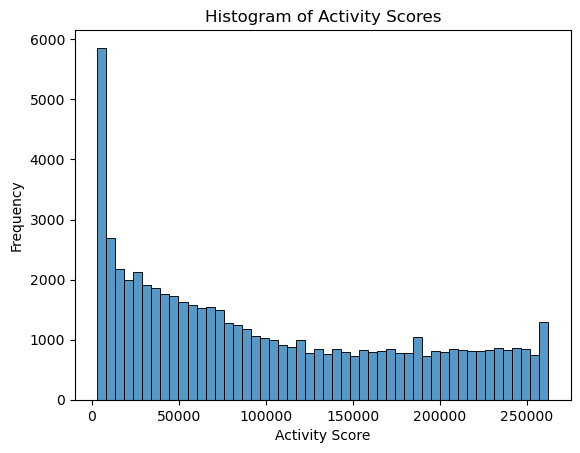

In [32]:
## Graphing Activity
sns.histplot(data=activities, x='Activity', bins=50, kde=False)
plt.xlabel('Activity Score')
plt.ylabel('Frequency')
plt.title('Histogram of Activity Scores')
plt.savefig(f'{dir}/Figs/{name}_ActivityScoreDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


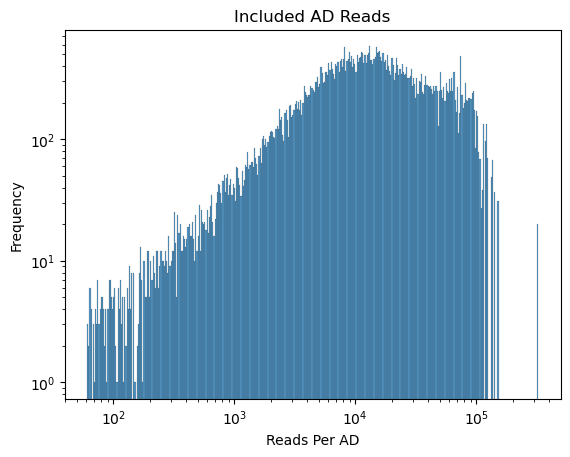

In [33]:
## Graphing AD reads

sns.histplot(data=total_reads_df, x='numreads_per_AD', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD')
plt.ylabel('Frequency')
plt.title('Included AD Reads')
plt.savefig(f'{dir}/Figs/{name}_ReadsDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


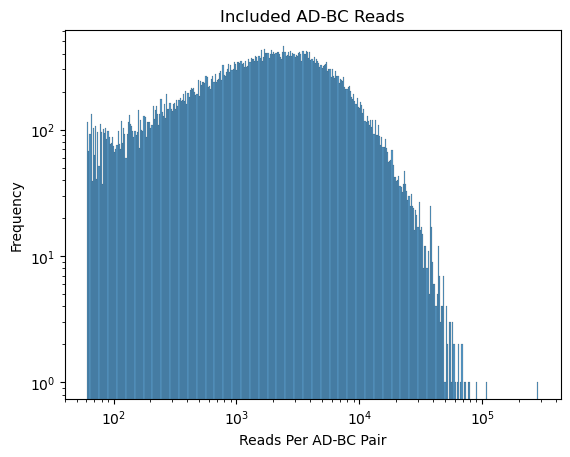

In [35]:
## Graphing AD-BC reads

sns.histplot(data=total_reads_df, x='Reads', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD-BC Pair')
plt.ylabel('Frequency')
plt.title('Included AD-BC Reads')
plt.savefig(f'{dir}/Figs/{name}_ADBCReadsDist.jpg')
plt.show()